In [4]:
### Follow the code to see how the ground state wavefunction overlap changes with disorder strength ####

### note this code shows how ground state wavefunction changes wit disorder in comparison to ground state wvfn at 0 dsiorder ###

In [5]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
from Minimal_Model_2D import *
import time

np.set_printoptions(threshold=sys.maxsize)

In [6]:
class Minimal_Model_Subband_Basis(twoD_Minimal_Model):

    def Ham(self, dis_mag=0, uncorr_var=1, lmbda=0, seed=None, kx=0, ky=0, phi=0):

        M = bmat([
           [self.H_same_spin(dis_mag, uncorr_var, lmbda, seed, kx, ky ), self.Del_array(phi) ],
           [self.Del_array(phi).conjugate(),-self.H_same_spin(dis_mag, uncorr_var, lmbda, seed, -kx, -ky).conjugate() ]
       ]) 

        return M
    
    def U_dag_ph(self, my=1):

        M = bmat([
            [ self.U_dag(my), None],
            [None, -self.U_dag(my).conjugate()],
        ])

        return M
    
    def Ham_changed_basis(self,  dis_mag=0, uncorr_var=1, lmbda=0, seed=None, kx=0, ky=0, phi=0, my=1):

        S_dag = self.U_dag_ph(my)

        S = self.U_dag_ph(my).transpose().conjugate()

        H = self.Ham(dis_mag, uncorr_var, lmbda, seed, kx, ky,phi)

        return S_dag.dot(H).dot(S)
    
    def Wvfn_overlap(self, V1, V2):

        ### returns overlap between wavefunction V1 and V2 ####

        V_ele_wse_product = np.multiply(np.conjugate(V1), V2)

        return np.sum(V_ele_wse_product) ### Reimann sum for 2D integration 

In [7]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 4.7              # lattice spacing in nm
AY = 4.6              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
#ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 4           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC


print(OMEGA/2, 3*OMEGA/2)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print(MU_SM)

UNCORR_VAR = 1167  ### uncorrelated variance of disorder

#LMBDA = np.array([0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1,1])
#LMBDA = np.linspace(0.075, 0.2, 51)
#LMBDA = np.linspace(0.15, 0.21, 81)
LMBDA=0
#SEED = 42  ## seed for the disorder
SEED = 58  ## seed for the disorder 


A = Minimal_Model_Subband_Basis(NTOT,NSM,NSC,M,AX,AY,OMEGA, delta=DELTA, meff_sc=MEFF_SC, meff_sm=MEFF_SM, mu_sm = MU_SM, mu_sc=MU_SC)
H = A.Ham(phi=PHI)
E, V= eigsh(H ,k=K_NUM ,sigma=0, return_eigenvectors=True)

sorted_index = np.argsort(E)

Esorted = E[sorted_index]/DELTA
Vsorted = V[:,sorted_index]

print(Esorted)

0.6631720133634798 1.9895160400904393
0.7958064160361757
[-0.83031863 -0.25455959  0.25455959  0.83031863]


In [8]:
print(A.Wvfn_overlap(Vsorted[:,2],Vsorted[:,2]))
print(np.abs(A.Wvfn_overlap(Vsorted[:,2],Vsorted[:,2])))

(1.000000000000002-1.925505942639408e-19j)
1.000000000000002


In [9]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 4.7              # lattice spacing in nm
AY = 4.6              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
#ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 4           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC


print(OMEGA/2, 3*OMEGA/2)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print(MU_SM)

UNCORR_VAR = 1167  ### uncorrelated variance of disorder

#LMBDA = np.array([0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1,1])
#LMBDA = np.linspace(0.075, 0.2, 51)
LMBDA = np.linspace(0.00, 0.25, 51)
#LMBDA=0
SEED = 58  ## seed for the disorder 

WV_OL_array =np.empty(LMBDA.shape, dtype=complex)

A = Minimal_Model_Subband_Basis(NTOT,NSM,NSC,M,AX,AY,OMEGA, delta=DELTA, meff_sc=MEFF_SC, meff_sm=MEFF_SM, mu_sm = MU_SM, mu_sc=MU_SC)

H = A.Ham(phi=PHI, uncorr_var=UNCORR_VAR, lmbda=0, seed=SEED)
E, V_ref= eigsh(H ,k=K_NUM ,sigma=0, return_eigenvectors=True)

sorted_index = np.argsort(E)

Esorted = E[sorted_index]/DELTA
Vsorted_ref = V_ref[:,sorted_index]
#WV_OL_array = A.Wvfn_overlap()

for i in range(LMBDA.shape[0]):

    H = A.Ham(phi=PHI, uncorr_var=UNCORR_VAR, lmbda=LMBDA[i], seed=SEED)
    E, V_f= eigsh(H ,k=K_NUM ,sigma=0, return_eigenvectors=True)
    sorted_index = np.argsort(E)
    Esorted = E[sorted_index]/DELTA
    Vsorted_f = V_f[:,sorted_index]
    WV_OL_array[i] = A.Wvfn_overlap(Vsorted_ref[:,K_NUM//2], Vsorted_f[:,K_NUM//2])
    print(i, WV_OL_array[i])

np.save('gs_wv_overlap_with_lmbda_{}_points.npy'.format(LMBDA.shape[0]), WV_OL_array)

0.6631720133634798 1.9895160400904393
0.7958064160361757
0 (-0.9903308918984413+0.13872535655620313j)
1 (0.329371960577405+0.9435629880363664j)
2 (-0.46060469207897237-0.8849166735523714j)
3 (-0.5242222066723565-0.8453233176772731j)
4 (0.9872694168825518+0.08137862875317625j)
5 (-0.13715380533822594+0.9759012438272727j)
6 (0.9745448371344274+0.09722534679507175j)
7 (0.8417775956367551+0.4868251112761581j)
8 (0.9451764340970069-0.1933588202608441j)
9 (-0.6994936093467147-0.6525309306045053j)
10 (0.019744143762279256+0.9479855055703588j)
11 (-0.11562463196510543+0.9325974551611067j)
12 (-0.6283835138761227+0.6875117528786394j)
13 (0.036170356654128905-0.9226087153865763j)
14 (-0.7448074605053293-0.5321804837594796j)
15 (-0.6193269072950106+0.6632754433528579j)
16 (0.30649570637422663-0.8453515045301627j)
17 (-0.19281777733956312+0.8690523595155178j)
18 (-0.783136037545885-0.40155084644527217j)
19 (0.15813749558752535-0.854232393373751j)
20 (-0.5557906028836128+0.6514647514253654j)
21 (0.

In [11]:
overlap_array = np.load('C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_effect_on_spin_Splitting\\gs_wv_overlap_with_lmbda_{}_points.npy'.format(LMBDA.shape[0]))

Text(0, 0.5, 'Ground state overlap')

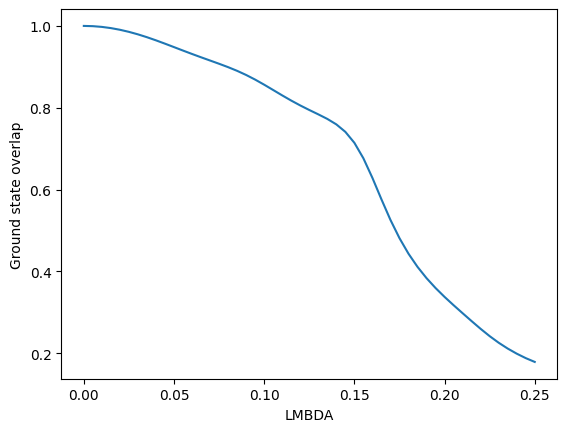

In [12]:
plt.plot(LMBDA, np.abs(overlap_array))
plt.xlabel('LMBDA')
plt.ylabel('Ground state overlap')